# Chapter 2 Hands-On Project: Matrices, Projections, Norms, Conditioning & Deep Learning Architectures

Welcome to the companion coding project for **Chapter 2: Matrix** of *Mathematics for AI & ML* ([https://math4ai.org](https://math4ai.org)).

In this notebook, we connect the core matrix theory and all **9 exercises** of Chapter 2 with runnable **NumPy** and **PyTorch** implementations:

1. **Part 1 — Matrix Products (2 Vector Views & 4 Matrix Views), Neural Layers & Attention Outer Products (Exercises 1 & 2)**:
   - Forward pass $\mathbf{h} = W\mathbf{x} + \mathbf{b}$ (column-combination view vs. row dot-product view), backward pass $W^\top \mathbf{g}$, and transpose reversal $(W\mathbf{x})^\top = \mathbf{x}^\top W^\top$.
   - All **4 Views of Matrix Multiplication** $AB$, Hadamard product ($A \odot B$) vs. matrix product ($AB$), and diagonal row/column scaling ($DA$ vs. $AD$).
   - Outer products in Transformer attention: $\alpha \mathbf{v} = (\mathbf{v}\mathbf{q}^\top)\mathbf{k}$, rank-1 outer products, and decomposing $A = Q^\top K = \sum_{l=0}^{d-1} \tilde{\mathbf{q}}_l \tilde{\mathbf{k}}_l^\top$.
2. **Part 2 — Subspace Projection Matrix (`Outer × Inverse-Inner`), Normal Equations & Ridge Regression (Exercise 4)**:
   - Comparing single-direction Frobenius projection vs. column-space projection matrix $P = X(X^\top X)^{-1}X^\top$ (symmetry, idempotency, and residual orthogonality).
   - **Ridge Regression ($\ell_2$-Regularized Least Squares)**: Quadratic expansion, finite-difference gradient check, curing singular/collinear $X^\top X$ via eigenvalue shifting ($\lambda_i(X^\top X) + \lambda \ge \lambda > 0$), and visualizing the Ridge regularization path from $\lambda \to 0^+$ to $\lambda \to \infty$.
3. **Part 3 — Matrix Norms ($\ell_1, \ell_\infty, \|\cdot\|_2, \|\cdot\|_F$, Schatten $p$-Norms) & Norm Inequalities (Exercises 3, 5 & 9)**:
   - Frobenius norm $\|W\|_F = \sqrt{\operatorname{tr}(W^\top W)}$, induced norms $\|W\|_1, \|W\|_\infty$, and the weight-decay gradient $\nabla_W(\lambda\|W\|_F^2) = 2\lambda W$.
   - Spectral norm $\|W\|_2 = \sqrt{\lambda_{\max}(W^\top W)} = \sigma_{\max}(W)$, spectral normalization $\tilde{W} = W/\|W\|_2$, and visualizing how $W$ stretches the unit circle into an ellipse.
   - **Schatten $p$-Norms** ($S_1$ Nuclear, $S_2$ Frobenius, $S_\infty$ Spectral) and **Exercise 9 Norm Bounds**: Frobenius–Spectral sandwich $\|A\|_2 \le \|A\|_F \le \sqrt{\min(M,N)}\|A\|_2$, sub-multiplicativity, triangle inequality, and deep product bound $\|W_L\cdots W_1\|_2 \le \alpha^L$.
4. **Part 4 — Orthonormal Initialization, Spectral Normalization & Adversarial Robustness (Exercises 6 & 7)**:
   - Orthonormal initialization ($W^\top W = I \implies \|W\|_2 = 1, \|W\|_F = \sqrt{N}$) preserving signal norms across 80-layer deep networks vs. exploding/vanishing weights.
   - Lipschitz bounds for linear and multi-layer ReLU networks ($L \le \prod_l \|W_l\|_2$) and PyTorch **Spectral Normalization** (`spectral_norm`) for 1-Lipschitz adversarial robustness.
5. **Part 5 — Condition Number $\kappa(A)$, Preconditioned Gradient Descent, LoRA & Softmax Attention Rank (Exercise 8 & Rank Theory)**:
   - Condition number $\kappa(A) = \|A\|_2\|A^{-1}\|_2 = \sigma_{\max}/\sigma_{\min}$, 1-step convergence when $\kappa(A)=1$ vs. slow zig-zagging when $\kappa(A) \gg 1$, and **Preconditioning** with $P = A^{-1/2}$ ($\kappa(P^\top A P) = 1$).
   - **Low-Rank Adaptation (LoRA)** $\Delta W = BA$ and why element-wise $\exp(QK^\top)$ + row-wise **Softmax** (and causal masking) break the rank-$d_k$ bottleneck in Transformers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Global reproducibility and plotting configuration
np.random.seed(42)
torch.manual_seed(42)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10
})
print(f"NumPy {np.__version__} | PyTorch {torch.__version__} — Environment ready!")

NumPy 2.4.6 | PyTorch 2.10.0+cu128 — Environment ready!


---
## Part 1: Matrix Products, Neural Network Layers & Attention Outer Products (Exercises 1 & 2)

### 1.1 Exercise 1: Forward Pass (Column vs. Row View), Backpropagation & Transpose Reversal

Given a linear layer with weight matrix $W \in \mathbb{R}^{3 \times 2}$, bias $\mathbf{b} \in \mathbb{R}^3$, input $\mathbf{x} \in \mathbb{R}^2$, and upstream gradient $\mathbf{g} = \nabla_{\mathbf{h}}\mathcal{L} \in \mathbb{R}^3$:
$$
W = \begin{bmatrix} 1 & 2 \\ 3 & 4 \\ 5 & 6 \end{bmatrix}, \qquad
\mathbf{b} = \begin{bmatrix} 1 \\ -1 \\ 0 \end{bmatrix}, \qquad
\mathbf{x} = \begin{bmatrix} 2 \\ -1 \end{bmatrix}, \qquad
\mathbf{g} = \begin{bmatrix} 1 \\ 2 \\ 3 \end{bmatrix}.
$$
- **Column-Combination View**: $W\mathbf{x} = x_0 \mathbf{w}_{:,0} + x_1 \mathbf{w}_{:,1} = 2\begin{bmatrix}1\\3\\5\end{bmatrix} - 1\begin{bmatrix}2\\4\\6\end{bmatrix} = \begin{bmatrix}0\\2\\4\end{bmatrix}$, so $\mathbf{h} = W\mathbf{x} + \mathbf{b} = \begin{bmatrix}1\\1\\4\end{bmatrix}$.
- **Row Dot-Product View**: $h_i = \mathbf{w}_{i,:}^\top \mathbf{x} + b_i$ for $i = 0, 1, 2$.
- **Backpropagation to Input**: $\nabla_{\mathbf{x}}\mathcal{L} = W^\top \mathbf{g} = \begin{bmatrix} 1 & 3 & 5 \\ 2 & 4 & 6 \end{bmatrix}\begin{bmatrix}1\\2\\3\end{bmatrix} = \begin{bmatrix}22\\28\end{bmatrix}$.
- **Transpose Reversal Identity**: $(W\mathbf{x})^\top = \mathbf{x}^\top W^\top = \begin{bmatrix} 0 & 2 & 4 \end{bmatrix}$.

In [2]:
# --- Exercise 1 Verification in NumPy & PyTorch Autograd ---
W = np.array([[1., 2.],
              [3., 4.],
              [5., 6.]])
b = np.array([1., -1., 0.])
x = np.array([2., -1.])
g = np.array([1., 2., 3.])

# 1. Forward pass: Matrix-vector product vs. Column-combination view vs. Row dot-product view
h_mat = W @ x + b
h_col = x[0] * W[:, 0] + x[1] * W[:, 1] + b
h_row = np.array([np.dot(W[i, :], x) + b[i] for i in range(W.shape[0])])

print("Exercise 1 — Neural Network Layer Operations:")
print(f"  h (W @ x + b):        {h_mat}")
print(f"  Column-view match:    {np.allclose(h_mat, h_col)} | Row-view match: {np.allclose(h_mat, h_row)}")

# 2. Backward pass: W^T g and PyTorch autograd check
grad_x = W.T @ g
x_t = torch.tensor(x, requires_grad=True)
W_t = torch.tensor(W, requires_grad=True)
b_t = torch.tensor(b, requires_grad=True)
g_t = torch.tensor(g)

h_t = W_t @ x_t + b_t
h_t.backward(g_t)  # Backpropagate upstream gradient g through h = Wx + b

print(f"  Backward W^T g:       {grad_x} | PyTorch x.grad: {x_t.grad.numpy()}")
print(f"  Weight grad g x^T:\n{np.outer(g, x)} | Matches W.grad: {np.allclose(np.outer(g, x), W_t.grad.numpy())}")

# 3. Transpose reversal (Wx)^T == x^T W^T (using explicit 2D column vector shape (2, 1))
x_col = x.reshape(-1, 1)
lhs = (W @ x_col).T
rhs = x_col.T @ W.T
print(f"  (Wx)^T = {lhs} == x^T W^T = {rhs}: {np.allclose(lhs, rhs)}")

# 4. All Four Views of Matrix Multiplication C = A @ B
A = np.array([[1., 2., 3.],
              [4., 5., 6.]])        # (2, 3)
B = np.array([[ 7.,  8.],
              [ 9., 10.],
              [11., 12.]])          # (3, 2)
C_std = A @ B
C_view1 = np.array([[np.dot(A[i, :], B[:, j]) for j in range(B.shape[1])] for i in range(A.shape[0])])
C_view2 = np.column_stack([A @ B[:, j] for j in range(B.shape[1])])
C_view3 = np.vstack([A[i, :] @ B for i in range(A.shape[0])])
C_view4 = sum(np.outer(A[:, l], B[l, :]) for l in range(A.shape[1]))
print(f"\nFour Views of Matrix Product AB all match C_std: "
      f"{np.allclose(C_std, C_view1) and np.allclose(C_std, C_view2) and np.allclose(C_std, C_view3) and np.allclose(C_std, C_view4)}")

Exercise 1 — Neural Network Layer Operations:
  h (W @ x + b):        [1. 1. 4.]
  Column-view match:    True | Row-view match: True
  Backward W^T g:       [22. 28.] | PyTorch x.grad: [22. 28.]
  Weight grad g x^T:
[[ 2. -1.]
 [ 4. -2.]
 [ 6. -3.]] | Matches W.grad: True
  (Wx)^T = [[0. 2. 4.]] == x^T W^T = [[0. 2. 4.]]: True

Four Views of Matrix Product AB all match C_std: True


### 1.2 Exercise 2: Outer Products in Attention Mechanisms & Sum of Rank-1 Matrices

For $\mathbf{q} = \begin{bmatrix}1\\2\end{bmatrix}$, $\mathbf{k} = \begin{bmatrix}3\\4\end{bmatrix}$, $\mathbf{v} = \begin{bmatrix}5\\6\end{bmatrix}$:
1. Raw score: $\alpha = \mathbf{q}^\top \mathbf{k} = 11$.
2. Associative rewrite: $\alpha \mathbf{v} = \mathbf{v}(\mathbf{q}^\top \mathbf{k}) = (\mathbf{v}\mathbf{q}^\top)\mathbf{k} = \begin{bmatrix}5 & 10\\6 & 12\end{bmatrix}\begin{bmatrix}3\\4\end{bmatrix} = \begin{bmatrix}55\\66\end{bmatrix}$ (the key algebraic trick behind **Linear Attention**, reducing $O(N^2 d)$ to $O(N d^2)$!).
3. Every outer product $\mathbf{u}\mathbf{v}^\top$ of nonzero vectors has $\operatorname{rank}(\mathbf{u}\mathbf{v}^\top) = 1$ because every column is a scalar multiple of $\mathbf{u}$.
4. For $Q = [\mathbf{q}_1, \mathbf{q}_2] \in \mathbb{R}^{d \times 2}$ and $K = [\mathbf{k}_1, \mathbf{k}_2] \in \mathbb{R}^{d \times 2}$, the raw attention matrix $A = Q^\top K = \sum_{l=0}^{d-1} \tilde{\mathbf{q}}_l \tilde{\mathbf{k}}_l^\top$ is a sum of $d$ rank-1 outer products over the feature dimension $d$.

In [3]:
# --- Exercise 2 Verification: Outer Products & Attention Matrix Decomposition ---
q = np.array([1., 2.])
k = np.array([3., 4.])
v = np.array([5., 6.])

# 1 & 2. Raw score alpha = q^T k and associative outer-product rewrite (v q^T) k
alpha = np.dot(q, k)
alpha_v = alpha * v
vq_outer = np.outer(v, q)
vq_k = vq_outer @ k

print("Exercise 2 — Outer Products in Attention:")
print(f"  1. Raw score alpha = q^T k = {alpha:.1f}")
print(f"  2. alpha * v = {alpha_v} | (v q^T) k = {vq_k} | Equal: {np.allclose(alpha_v, vq_k)}")
print(f"  3. v q^T =\n{vq_outer}\n     rank(v q^T) = {np.linalg.matrix_rank(vq_outer)}")

# 4. Batch attention A = Q^T K decomposed as sum of rank-1 outer products along inner dimension d
d, n_tokens = 3, 2
Q = np.array([[1., 2.],
              [3., 4.],
              [5., 6.]])   # shape (d=3, 2): columns are q_1, q_2; rows are feature slices q_tilde_l
K = np.array([[ 2., -1.],
              [ 0.,  3.],
              [ 1.,  2.]])  # shape (d=3, 2): columns are k_1, k_2; rows are feature slices k_tilde_l

A_direct = Q.T @ K
rank1_layers = [np.outer(Q[l, :], K[l, :]) for l in range(d)]
A_sum_rank1 = sum(rank1_layers)

print(f"\n  4. Batch Attention A = Q^T K (shape {A_direct.shape}):\n{A_direct}")
print(f"     Ranks of each feature outer-product layer: {[np.linalg.matrix_rank(M) for M in rank1_layers]}")
print(f"     Sum of {d} rank-1 outer products matches Q^T K: {np.allclose(A_direct, A_sum_rank1)}")

Exercise 2 — Outer Products in Attention:
  1. Raw score alpha = q^T k = 11.0
  2. alpha * v = [55. 66.] | (v q^T) k = [55. 66.] | Equal: True
  3. v q^T =
[[ 5. 10.]
 [ 6. 12.]]
     rank(v q^T) = 1

  4. Batch Attention A = Q^T K (shape (2, 2)):
[[ 7. 18.]
 [10. 22.]]
     Ranks of each feature outer-product layer: [np.int64(1), np.int64(1), np.int64(1)]
     Sum of 3 rank-1 outer products matches Q^T K: True


---
## Part 2: Subspace Projection Matrix (`Outer × Inverse-Inner`) & Ridge Regression (Exercise 4)

### 2.1 Two Kinds of Matrix Projection: Single Direction vs. Column Space

As introduced in Chapter 2, remember the structural mnemonic connecting vector and matrix projections:
1. **Projecting Matrix $A$ onto a Single Matrix Direction $B$** (same shape, using the Frobenius inner product $\langle A, B\rangle_F = \operatorname{tr}(B^\top A)$):
   $$\operatorname{proj}_B(A) = \frac{\operatorname{tr}(B^\top A)}{\operatorname{tr}(B^\top B)} B$$
2. **Projecting onto the Column Space $\mathcal{C}(X)$ of $X \in \mathbb{R}^{N \times d}$** (full column rank):
   $$P_X = \underbrace{X}_{\text{Outer}} \; \underbrace{(X^\top X)^{-1}}_{\text{Inverse-Inner}} \; \underbrace{X^\top}_{\text{Outer}^\top}, \qquad \hat{\mathbf{y}} = P_X \mathbf{y}$$
   When $X = \mathbf{x}$ is a single column vector, $X(X^\top X)^{-1}X^\top = \frac{\mathbf{x}\mathbf{x}^\top}{\mathbf{x}^\top\mathbf{x}}$ (`Outer / Inner`). When $X = Q$ has orthonormal columns ($Q^\top Q = I$), $P_Q = QQ^\top$.

### 2.2 Exercise 4: Normal Equations, Ridge Regression & Fixing Collinear Singularity

For the Ridge objective $\mathcal{L}(\boldsymbol{\theta}) = \|X\boldsymbol{\theta} - \mathbf{y}\|_2^2 + \lambda \|\boldsymbol{\theta}\|_2^2$ ($\lambda > 0$):
- **Quadratic Expansion**: $\mathcal{L}(\boldsymbol{\theta}) = \boldsymbol{\theta}^\top(X^\top X + \lambda I)\boldsymbol{\theta} - 2\boldsymbol{\theta}^\top X^\top \mathbf{y} + \mathbf{y}^\top \mathbf{y}$
- **Gradient & Closed-Form Optimum**: $\nabla_{\boldsymbol{\theta}}\mathcal{L} = 2(X^\top X + \lambda I)\boldsymbol{\theta} - 2X^\top \mathbf{y} = \mathbf{0} \implies \hat{\boldsymbol{\theta}}_{\text{ridge}} = (X^\top X + \lambda I)^{-1}X^\top \mathbf{y}$
- **Universal Invertibility**: Since $X^\top X \succeq 0$, shifting by $\lambda I$ shifts every eigenvalue to $\lambda_i(X^\top X) + \lambda \ge \lambda > 0$, making $X^\top X + \lambda I$ strictly positive definite even when $X$ has duplicated or collinear columns!

Column-Space Projection Matrix P = X (X^T X)^{-1} X^T:
  Symmetric (P^T == P):      True
  Idempotent (P^2 == P):     True
  Residual orthogonal X^T r: True (max |X^T r| = 3.11e-15)
  rank(P_X) = tr(P_X) =      2.0 == d = 2

Exercise 4 — Normal Equations & Ridge Regression:
  1. L_direct = 5.692081 vs. L_expanded = 5.692081 (Match: True)
  2. Gradient match (analytic vs. finite diff): True
  3. Collinear X^T X rank = 1/3 | eigenvalues = [ -0.  -0. 770.]
  4. Shifted (X^T X + 0.1 I) rank = 3/3 | eigenvalues = [1.000e-01 1.000e-01 7.701e+02] >= 0.1
     Unique Ridge solution on singular design: [-0.016  -0.032  -0.0481]


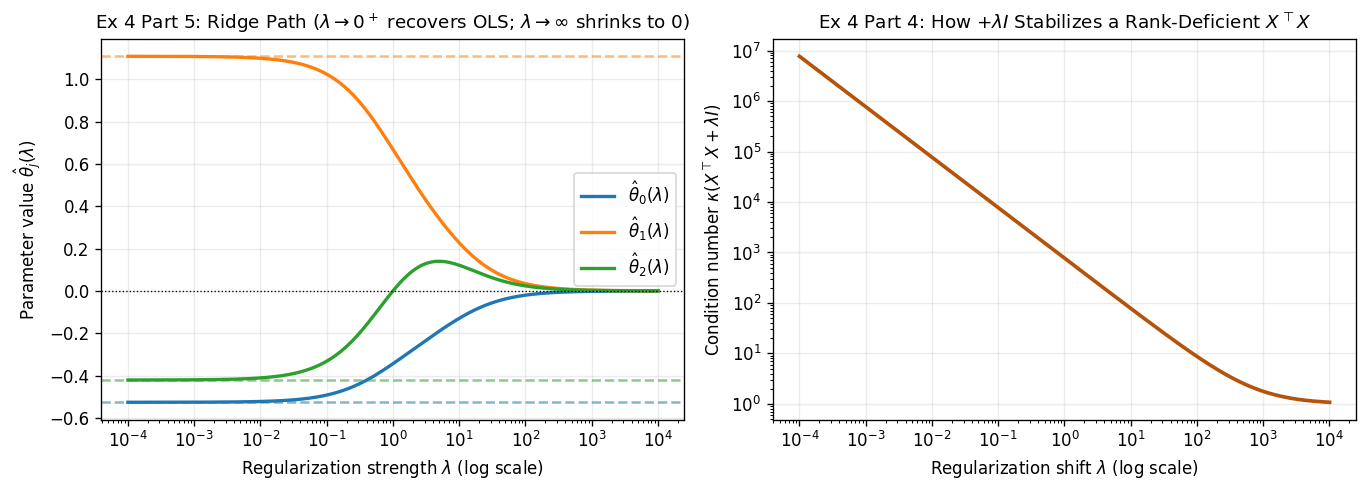

In [4]:
# --- 2.1 Column-Space Projection Matrix P_X vs. Frobenius Single-Direction Projection ---
X_full = np.array([[1., 0.],
                   [1., 1.],
                   [1., 2.],
                   [1., 3.]])
y_vec = np.array([1.2, 1.9, 3.2, 3.8])

# Column-space projection matrix: Outer * Inverse-Inner * Outer^T
P_X = X_full @ np.linalg.inv(X_full.T @ X_full) @ X_full.T
y_hat = P_X @ y_vec
r_perp = y_vec - y_hat

print("Column-Space Projection Matrix P = X (X^T X)^{-1} X^T:")
print(f"  Symmetric (P^T == P):      {np.allclose(P_X.T, P_X)}")
print(f"  Idempotent (P^2 == P):     {np.allclose(P_X @ P_X, P_X)}")
print(f"  Residual orthogonal X^T r: {np.allclose(X_full.T @ r_perp, 0)} (max |X^T r| = {np.max(np.abs(X_full.T @ r_perp)):.2e})")
print(f"  rank(P_X) = tr(P_X) =      {np.trace(P_X):.1f} == d = {X_full.shape[1]}")

# --- 2.2 Exercise 4 Complete Verification ---
np.random.seed(42)
X = np.random.randn(5, 3)
y = np.random.randn(5)
lam = 0.1
theta = np.array([0.4, -0.3, 0.7])
XtX, Xty, yty, I3 = X.T @ X, X.T @ y, y.T @ y, np.eye(3)

# Part 1: Quadratic expansion check
L_direct = np.linalg.norm(X @ theta - y)**2 + lam * np.linalg.norm(theta)**2
L_expanded = theta.T @ (XtX + lam * I3) @ theta - 2 * theta.T @ Xty + yty

# Part 2: Analytical vs. Central Finite-Difference Gradient
grad_analytic = 2 * (XtX + lam * I3) @ theta - 2 * Xty
eps = 1e-6
loss_fn = lambda t: np.sum((X @ t - y)**2) + lam * np.sum(t**2)
grad_numeric = np.array([(loss_fn(theta + eps * e) - loss_fn(theta - eps * e)) / (2 * eps) for e in I3])

# Parts 3 & 4: Singular / Collinear Design Matrix cured by +lam * I
X_sing = np.array([[1., 2., 3.],
                   [2., 4., 6.],
                   [3., 6., 9.],
                   [4., 8., 12.],
                   [5., 10., 15.]])  # cols 2 and 3 are multiples of col 1 -> rank 1!
XtX_sing = X_sing.T @ X_sing
eigs_sing = np.linalg.eigvalsh(XtX_sing)
eigs_shifted = np.linalg.eigvalsh(XtX_sing + lam * I3)
theta_ridge_sing = np.linalg.solve(XtX_sing + lam * I3, X_sing.T @ y)

print("\nExercise 4 — Normal Equations & Ridge Regression:")
print(f"  1. L_direct = {L_direct:.6f} vs. L_expanded = {L_expanded:.6f} (Match: {np.isclose(L_direct, L_expanded)})")
print(f"  2. Gradient match (analytic vs. finite diff): {np.allclose(grad_analytic, grad_numeric, atol=1e-6)}")
print(f"  3. Collinear X^T X rank = {np.linalg.matrix_rank(XtX_sing)}/3 | eigenvalues = {eigs_sing.round(4)}")
print(f"  4. Shifted (X^T X + 0.1 I) rank = {np.linalg.matrix_rank(XtX_sing + lam * I3)}/3 | eigenvalues = {eigs_shifted.round(4)} >= {lam}")
print(f"     Unique Ridge solution on singular design: {theta_ridge_sing.round(4)}")

# Part 5: Asymptotic limits lambda -> 0+ (OLS) and lambda -> inf (0)
theta_ols = np.linalg.solve(XtX, Xty)
lambdas = np.logspace(-4, 4, 200)
thetas_path = np.array([np.linalg.solve(XtX + l * I3, Xty) for l in lambdas])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for j in range(3):
    axes[0].semilogx(lambdas, thetas_path[:, j], lw=2, label=rf"$\hat{{\theta}}_{j}(\lambda)$")
    axes[0].axhline(theta_ols[j], color=f"C{j}", ls="--", alpha=0.55)
axes[0].axhline(0, color="black", lw=0.8, ls=":")
axes[0].set_xlabel(r"Regularization strength $\lambda$ (log scale)")
axes[0].set_ylabel(r"Parameter value $\hat{\theta}_j(\lambda)$")
axes[0].set_title(r"Ex 4 Part 5: Ridge Path ($\lambda \to 0^+$ recovers OLS; $\lambda \to \infty$ shrinks to $0$)")
axes[0].legend()

cond_sing_shifted = [np.linalg.cond(XtX_sing + l * I3) for l in lambdas]
axes[1].loglog(lambdas, cond_sing_shifted, color="#b45309", lw=2.2)
axes[1].set_xlabel(r"Regularization shift $\lambda$ (log scale)")
axes[1].set_ylabel(r"Condition number $\kappa(X^\top X + \lambda I)$")
axes[1].set_title(r"Ex 4 Part 4: How $+\lambda I$ Stabilizes a Rank-Deficient $X^\top X$")
plt.tight_layout()
plt.show()

---
## Part 3: Matrix Norms ($\ell_1, \ell_\infty, \|\cdot\|_2, \|\cdot\|_F$, Schatten $p$-Norms) & Bounds (Exercises 3, 5 & 9)

### 3.1 Exercise 3 ($\ell_2$ Weight Decay & Frobenius Norm) and Exercise 5 (Spectral Norm & SVD)

- **Exercise 3**: For $W = \begin{bmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \end{bmatrix}$,
  $$\|W\|_F = \sqrt{\sum_{i,j} w_{ij}^2} = \sqrt{\operatorname{tr}(W^\top W)} = \sqrt{91} \approx 9.5394, \quad \|W\|_1 = 9, \quad \|W\|_\infty = 15, \quad \nabla_W(\lambda\|W\|_F^2) = 2\lambda W.$$
- **Exercise 5**: For $W = \begin{bmatrix} 2 & 1 \\ 1 & 2 \end{bmatrix}$, $W^\top W = \begin{bmatrix} 5 & 4 \\ 4 & 5 \end{bmatrix}$ has eigenvalues $\lambda_1 = 9, \lambda_2 = 1$, so
  $$\|W\|_2 = \sqrt{\lambda_{\max}(W^\top W)} = \sigma_{\max}(W) = 3, \qquad \tilde{W} = \frac{W}{\|W\|_2} \implies \|\tilde{W}\|_2 = 1.$$
- **Schatten $p$-Norm Family**: Applying the vector $\ell_p$ norm to the singular value vector $\boldsymbol{\sigma}(A) = [\sigma_1, \dots, \sigma_r]^\top$ unifies:
  - **Nuclear / Trace Norm ($p=1$)**: $\|A\|_{S_1} = \|A\|_* = \sum_{i=1}^r \sigma_i$ (convex surrogate for low rank)
  - **Frobenius Norm ($p=2$)**: $\|A\|_{S_2} = \|A\|_F = \sqrt{\sum_{i=1}^r \sigma_i^2}$ (weight decay energy)
  - **Spectral Norm ($p=\infty$)**: $\|A\|_{S_\infty} = \|A\|_2 = \sigma_{\max}(A)$ (worst-case stretch / Lipschitz constant)

Exercise 3 — Frobenius Norm, Induced Norms & Weight Decay:
  ||W||_F = sqrt(91) = 9.539392 | np.linalg.norm: 9.539392 | tr(W^T W) = 91.0
  ||W||_1 (max col sum) = 9.0 | ||W||_inf (max row sum) = 15.0
  Weight decay grad 2*lam*W matches PyTorch autograd: True

Exercise 5 — Spectral Norm & Singular Values:
  Eigenvalues of W^T W: [9. 1.] -> sqrt(lambda_max) = 3.0
  Singular values of W: [3. 1.] -> ||W||_2 = 3.0
  Spectrally normalized W_tilde = W / ||W||_2 has ||W_tilde||_2 = 1.000000


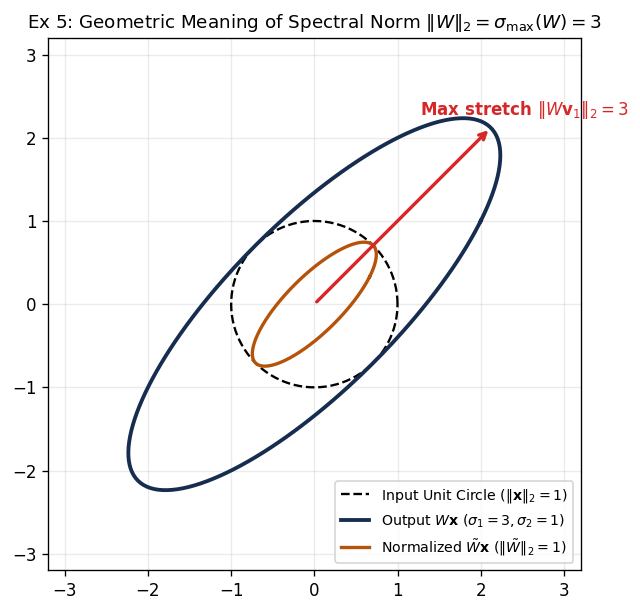

In [5]:
# --- Exercise 3 Verification: Frobenius Norm, Induced 1/Inf Norms & Weight Decay Gradient ---
W3 = np.array([[1., 2., 3.],
               [4., 5., 6.]])
fro_def = np.sqrt(np.sum(W3**2))
fro_np = np.linalg.norm(W3, ord='fro')
tr_WtW = np.trace(W3.T @ W3)
norm_1 = np.linalg.norm(W3, ord=1)        # max column sum: max(5, 7, 9) = 9
norm_inf = np.linalg.norm(W3, ord=np.inf) # max row sum: max(6, 15) = 15

# PyTorch autograd check for grad_W (lambda ||W||_F^2) = 2 * lambda * W
lam3 = 0.25
W3_t = torch.tensor(W3, requires_grad=True)
penalty = lam3 * torch.sum(W3_t ** 2)
penalty.backward()

print("Exercise 3 — Frobenius Norm, Induced Norms & Weight Decay:")
print(f"  ||W||_F = sqrt(91) = {fro_def:.6f} | np.linalg.norm: {fro_np:.6f} | tr(W^T W) = {tr_WtW:.1f}")
print(f"  ||W||_1 (max col sum) = {norm_1:.1f} | ||W||_inf (max row sum) = {norm_inf:.1f}")
print(f"  Weight decay grad 2*lam*W matches PyTorch autograd: {np.allclose(2 * lam3 * W3, W3_t.grad.numpy())}")

# --- Exercise 5 Verification: Spectral Norm, Singular Values & Spectral Normalization ---
W5 = np.array([[2., 1.],
               [1., 2.]])
WtW5 = W5.T @ W5
eigvals5 = np.sort(np.linalg.eigvalsh(WtW5))[::-1]
svd_s5 = np.linalg.svd(W5, compute_uv=False)
spec_norm5 = np.linalg.norm(W5, ord=2)
W5_tilde = W5 / spec_norm5

print("\nExercise 5 — Spectral Norm & Singular Values:")
print(f"  Eigenvalues of W^T W: {eigvals5} -> sqrt(lambda_max) = {np.sqrt(eigvals5[0]):.1f}")
print(f"  Singular values of W: {svd_s5} -> ||W||_2 = {spec_norm5:.1f}")
print(f"  Spectrally normalized W_tilde = W / ||W||_2 has ||W_tilde||_2 = {np.linalg.norm(W5_tilde, ord=2):.6f}")

# Visualize how W5 and W5_tilde deform the unit circle {||x||_2 = 1}
angles = np.linspace(0, 2 * np.pi, 300)
unit_circle = np.vstack([np.cos(angles), np.sin(angles)])  # (2, 300)
ellipse_W = W5 @ unit_circle
ellipse_W_tilde = W5_tilde @ unit_circle

fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot(unit_circle[0], unit_circle[1], "k--", lw=1.4, label=r"Input Unit Circle ($\|\mathbf{x}\|_2 = 1$)")
ax.plot(ellipse_W[0], ellipse_W[1], color="#162d50", lw=2.3, label=r"Output $W\mathbf{x}$ ($\sigma_1=3, \sigma_2=1$)")
ax.plot(ellipse_W_tilde[0], ellipse_W_tilde[1], color="#b45309", lw=2.0, label=r"Normalized $\tilde{W}\mathbf{x}$ ($\|\tilde{W}\|_2=1$)")
# Top right singular vector v_1 = [1/sqrt(2), 1/sqrt(2)]^T stretched by sigma_1 = 3
v1 = np.array([1.0, 1.0]) / np.sqrt(2)
Wv1 = W5 @ v1
ax.annotate("", xy=Wv1, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#d62728", lw=2))
ax.text(Wv1[0] - 0.85, Wv1[1] + 0.15, r"Max stretch $\|W\mathbf{v}_1\|_2 = 3$", color="#d62728", fontweight="bold")
ax.set_aspect("equal")
ax.set_xlim(-3.2, 3.2)
ax.set_ylim(-3.2, 3.2)
ax.set_title(r"Ex 5: Geometric Meaning of Spectral Norm $\|W\|_2 = \sigma_{\max}(W) = 3$")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

In [6]:
# --- Exercise 9 Verification: Matrix Norm Inequalities & Multi-Layer Explosion Bound ---
np.random.seed(42)

# 1. Frobenius-Spectral Sandwich: ||A||_2 <= ||A||_F <= sqrt(min(M, N)) ||A||_2
A_rand = np.random.randn(4, 6)
r = min(A_rand.shape)
n2, nF = np.linalg.norm(A_rand, ord=2), np.linalg.norm(A_rand, ord='fro')

# Equality case 1: Rank-1 matrix -> ||A||_2 == ||A||_F
u, v = np.random.randn(4), np.random.randn(6)
A_rank1 = np.outer(u, v)
# Equality case 2: Scaled orthonormal columns -> ||A||_F == sqrt(r) ||A||_2
Q_orth, _ = np.linalg.qr(np.random.randn(6, 4))
A_iso = 2.5 * Q_orth.T  # shape (4, 6), all 4 singular values equal 2.5

print("Exercise 9 — Matrix Norm Inequalities & Bounds:")
print(f"  1. Random 4x6: ||A||_2 = {n2:.4f} <= ||A||_F = {nF:.4f} <= sqrt(4)||A||_2 = {np.sqrt(r)*n2:.4f}")
print(f"     Rank-1 lower equality ||A||_2 == ||A||_F: "
      f"{np.isclose(np.linalg.norm(A_rank1, 2), np.linalg.norm(A_rank1, 'fro'))}")
print(f"     Scaled-orthonormal upper equality ||A||_F == sqrt(r)||A||_2: "
      f"{np.isclose(np.linalg.norm(A_iso, 'fro'), np.sqrt(r) * np.linalg.norm(A_iso, 2))}")

# 2 & 3. Sub-multiplicativity and Triangle Inequality
B_rand = np.random.randn(6, 5)
C_rand = np.random.randn(4, 6)
sub_fro = np.linalg.norm(A_rand @ B_rand, 'fro') <= np.linalg.norm(A_rand, 'fro') * np.linalg.norm(B_rand, 'fro')
sub_spec = np.linalg.norm(A_rand @ B_rand, 2) <= np.linalg.norm(A_rand, 2) * np.linalg.norm(B_rand, 2)
tri_fro = np.linalg.norm(A_rand + C_rand, 'fro') <= np.linalg.norm(A_rand, 'fro') + np.linalg.norm(C_rand, 'fro')
tri_spec = np.linalg.norm(A_rand + C_rand, 2) <= np.linalg.norm(A_rand, 2) + np.linalg.norm(C_rand, 2)
print(f"  2. Sub-multiplicativity (Frobenius & Spectral): {sub_fro and sub_spec}")
print(f"  3. Triangle Inequality (Frobenius & Spectral):  {tri_fro and tri_spec}")

# 4. Multi-layer product bound: ||W_L ... W_1||_2 <= alpha^L for alpha = 1.5
L_layers, alpha = 6, 1.5
W_prod = np.eye(5)
for _ in range(L_layers):
    W_i = np.random.randn(5, 5)
    W_i = alpha * (W_i / np.linalg.norm(W_i, ord=2))
    W_prod = W_i @ W_prod
print(f"  4. {L_layers}-layer product: ||W_L...W_1||_2 = {np.linalg.norm(W_prod, 2):.4f} <= alpha^L = {alpha**L_layers:.4f}")

# Bonus: Schatten p-Norm hierarchy ||A||_{S_p} = (sum sigma_i^p)^{1/p}
S1_nuclear = np.linalg.norm(A_rand, ord='nuc')
S2_fro = np.linalg.norm(A_rand, ord='fro')
Sinf_spec = np.linalg.norm(A_rand, ord=2)
print(f"\nSchatten p-Norms on A_rand (via singular values): "
      f"S_1 (Nuclear) = {S1_nuclear:.4f} >= S_2 (Frobenius) = {S2_fro:.4f} >= S_inf (Spectral) = {Sinf_spec:.4f}")

Exercise 9 — Matrix Norm Inequalities & Bounds:
  1. Random 4x6: ||A||_2 = 2.9709 <= ||A||_F = 4.7257 <= sqrt(4)||A||_2 = 5.9418
     Rank-1 lower equality ||A||_2 == ||A||_F: True
     Scaled-orthonormal upper equality ||A||_F == sqrt(r)||A||_2: True
  2. Sub-multiplicativity (Frobenius & Spectral): True
  3. Triangle Inequality (Frobenius & Spectral):  True
  4. 6-layer product: ||W_L...W_1||_2 = 1.3763 <= alpha^L = 11.3906

Schatten p-Norms on A_rand (via singular values): S_1 (Nuclear) = 8.9242 >= S_2 (Frobenius) = 4.7257 >= S_inf (Spectral) = 2.9709


---
## Part 4: Orthonormal Initialization, Lipschitz Bounds & Adversarial Robustness (Exercises 6 & 7)

### 4.1 Exercise 6: Orthonormal Initialization ($W^\top W = I$) Preserves Norms Across Deep Stacks
For an orthonormal matrix $W \in \mathbb{R}^{N \times N}$ ($W^\top W = I$):
1. $\|W\|_2 = \sqrt{\lambda_{\max}(I)} = 1$ and $\|W\|_F = \sqrt{\operatorname{tr}(I)} = \sqrt{N}$.
2. Isometry: $\|W\mathbf{x}\|_2^2 = \mathbf{x}^\top W^\top W \mathbf{x} = \|\mathbf{x}\|_2^2$.
3. Across $L$ layers $f(\mathbf{x}) = W_L \cdots W_1 \mathbf{x}$, the product $W_L \cdots W_1$ remains orthonormal, so $\|f(\mathbf{x})\|_2 = \|\mathbf{x}\|_2$ — preventing vanishing and exploding activations/gradients!

### 4.2 Exercise 7: Lipschitz Constants, ReLU Networks & Spectral Normalization
- A linear layer $f(\mathbf{x}) = W\mathbf{x}$ has exact minimum Lipschitz constant $L = \|W\|_2$.
- Since ReLU $\sigma(z) = \max(0, z)$ is 1-Lipschitz ($\|\sigma(\mathbf{u}) - \sigma(\mathbf{v})\|_2 \le \|\mathbf{u} - \mathbf{v}\|_2$), a deep network $f(\mathbf{x}) = W_L \sigma(W_{L-1}\cdots \sigma(W_1 \mathbf{x}))$ has Lipschitz constant bounded by $\prod_{l=1}^L \|W_l\|_2$.
- Enforcing $\|W_l\|_2 \le 1$ via **Spectral Normalization** guarantees that the entire deep network is **1-Lipschitz**: $\|f(\mathbf{x} + \boldsymbol{\delta}) - f(\mathbf{x})\|_2 \le \|\boldsymbol{\delta}\|_2$.

Exercise 6 — Orthonormal Matrices & Deep Signal Stability:
  ||W||_2 = 1.000000 (Expected: 1.0)
  ||W||_F = 5.656854 (Expected: sqrt(32) = 5.656854)
  Single-layer isometry ||Wx0||_2 = 5.000000 == ||x0||_2 = 5.000000

Exercise 7 — Lipschitz Bounds & Adversarial Robustness:
  2-Layer ReLU Empirical Max Stretch: 18.5462 <= Theoretical ||W2||_2 ||W1||_2 = 77.7348
  4-Layer Spectral-Norm ReLU Net Max Perturbation Ratio ||f(x+d)-f(x)||_2 / ||d||_2 = 0.0397 <= 1.0


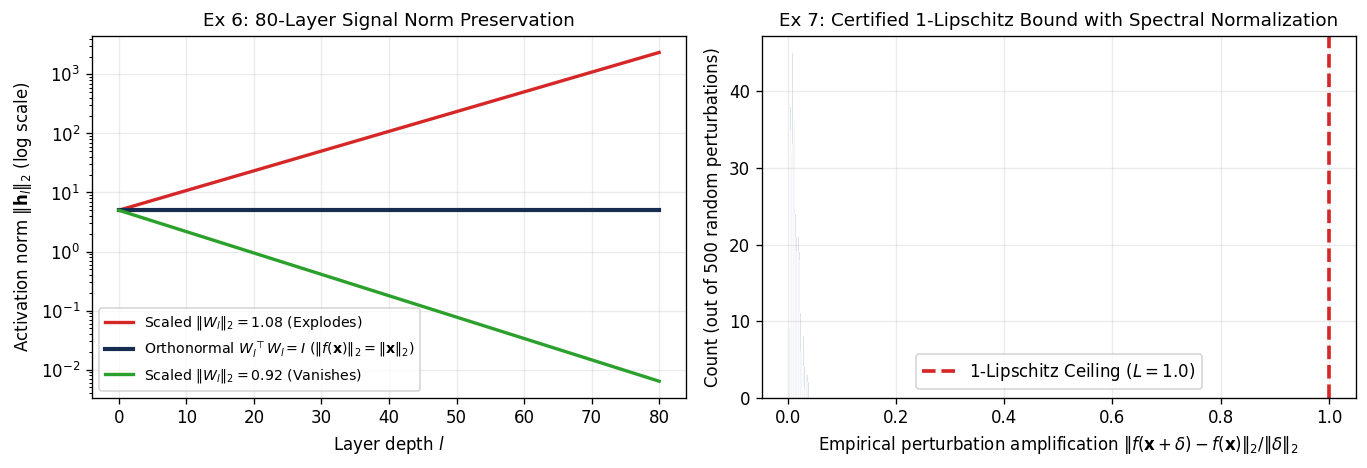

In [7]:
# --- Exercise 6 Verification: Orthonormal Initialization Across L = 80 Deep Layers ---
torch.manual_seed(42)
N_dim, L_depth = 32, 80
x0 = torch.randn(N_dim)
x0 = x0 / torch.linalg.vector_norm(x0) * 5.0  # ||x0||_2 = 5.0

# Single orthonormal matrix check
W_orth = torch.empty(N_dim, N_dim)
nn.init.orthogonal_(W_orth)
print("Exercise 6 — Orthonormal Matrices & Deep Signal Stability:")
print(f"  ||W||_2 = {torch.linalg.matrix_norm(W_orth, ord=2).item():.6f} (Expected: 1.0)")
print(f"  ||W||_F = {torch.linalg.matrix_norm(W_orth, ord='fro').item():.6f} (Expected: sqrt({N_dim}) = {np.sqrt(N_dim):.6f})")
print(f"  Single-layer isometry ||Wx0||_2 = {torch.linalg.vector_norm(W_orth @ x0).item():.6f} == ||x0||_2 = {torch.linalg.vector_norm(x0).item():.6f}")

# Compare 80-layer norm evolution: Orthonormal vs. Slightly Sub-critical vs. Slightly Super-critical
norms_orth, norms_vanish, norms_explode = [x0.norm().item()], [x0.norm().item()], [x0.norm().item()]
h_o, h_v, h_e = x0.clone(), x0.clone(), x0.clone()
for _ in range(L_depth):
    Wi = torch.empty(N_dim, N_dim)
    nn.init.orthogonal_(Wi)
    h_o = Wi @ h_o
    h_v = (0.92 * Wi) @ h_v
    h_e = (1.08 * Wi) @ h_e
    norms_orth.append(h_o.norm().item())
    norms_vanish.append(h_v.norm().item())
    norms_explode.append(h_e.norm().item())

# --- Exercise 7 Verification: Lipschitz Constants & 1-Lipschitz Adversarial Perturbation Bound ---
d_in, d_hid, d_out = 16, 32, 8
W1 = torch.randn(d_hid, d_in)
W2 = torch.randn(d_out, d_hid)
L_bound_2layer = (torch.linalg.matrix_norm(W1, ord=2) * torch.linalg.matrix_norm(W2, ord=2)).item()

# Test 500 random pairs (x, y) on 2-layer ReLU network g(x) = W2 ReLU(W1 x)
X_pairs = torch.randn(500, d_in)
Y_pairs = torch.randn(500, d_in)
g_X = torch.relu(X_pairs @ W1.T) @ W2.T
g_Y = torch.relu(Y_pairs @ W1.T) @ W2.T
ratios_2layer = (torch.linalg.vector_norm(g_X - g_Y, dim=1) / torch.linalg.vector_norm(X_pairs - Y_pairs, dim=1)).max().item()

# 4-layer Spectrally Normalized 1-Lipschitz ReLU Network
layers_sn = []
for _ in range(4):
    lin = nn.Linear(d_in, d_in, bias=False)
    nn.init.normal_(lin.weight, std=0.8)
    layers_sn.append(nn.utils.parametrizations.spectral_norm(lin))
    layers_sn.append(nn.ReLU())
net_1lip = nn.Sequential(*layers_sn)

with torch.no_grad():
    delta = 0.5 * torch.randn(500, d_in)
    out_diff = torch.linalg.vector_norm(net_1lip(X_pairs + delta) - net_1lip(X_pairs), dim=1)
    in_diff = torch.linalg.vector_norm(delta, dim=1)
    max_lip_ratio_sn = (out_diff / in_diff).max().item()

print("\nExercise 7 — Lipschitz Bounds & Adversarial Robustness:")
print(f"  2-Layer ReLU Empirical Max Stretch: {ratios_2layer:.4f} <= Theoretical ||W2||_2 ||W1||_2 = {L_bound_2layer:.4f}")
print(f"  4-Layer Spectral-Norm ReLU Net Max Perturbation Ratio ||f(x+d)-f(x)||_2 / ||d||_2 = {max_lip_ratio_sn:.4f} <= 1.0")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
axes[0].semilogy(range(L_depth + 1), norms_explode, color="#d62728", lw=2, label=r"Scaled $\|W_l\|_2 = 1.08$ (Explodes)")
axes[0].semilogy(range(L_depth + 1), norms_orth, color="#162d50", lw=2.5, label=r"Orthonormal $W_l^\top W_l = I$ ($\|f(\mathbf{x})\|_2 = \|\mathbf{x}\|_2$)")
axes[0].semilogy(range(L_depth + 1), norms_vanish, color="#2ca02c", lw=2, label=r"Scaled $\|W_l\|_2 = 0.92$ (Vanishes)")
axes[0].set_xlabel(r"Layer depth $l$")
axes[0].set_ylabel(r"Activation norm $\|\mathbf{h}_l\|_2$ (log scale)")
axes[0].set_title("Ex 6: 80-Layer Signal Norm Preservation")
axes[0].legend(fontsize=8.5)

axes[1].hist((out_diff / in_diff).numpy(), bins=30, color="#2b548a", alpha=0.8, edgecolor="white")
axes[1].axvline(1.0, color="#d62728", lw=2.2, ls="--", label="1-Lipschitz Ceiling ($L = 1.0$)")
axes[1].set_xlabel(r"Empirical perturbation amplification $\|f(\mathbf{x}+\delta) - f(\mathbf{x})\|_2 / \|\delta\|_2$")
axes[1].set_ylabel("Count (out of 500 random perturbations)")
axes[1].set_title("Ex 7: Certified 1-Lipschitz Bound with Spectral Normalization")
axes[1].legend()
plt.tight_layout()
plt.show()

---
## Part 5: Condition Number $\kappa(A)$, Preconditioning, LoRA & Softmax Attention Rank (Exercise 8 & Rank)

### 5.1 Exercise 8: Condition Number $\kappa(A) = \|A\|_2\|A^{-1}\|_2$ & Preconditioned Gradient Descent
- For $A = \begin{bmatrix} 2 & 1 \\ 1 & 2 \end{bmatrix}$, $\lambda_1 = 3, \lambda_2 = 1 \implies \kappa(A) = \|A\|_2 \|A^{-1}\|_2 = 3 \times 1 = 3$.
- On $f(\mathbf{x}) = \frac{1}{2}\mathbf{x}^\top A\mathbf{x} - \mathbf{b}^\top \mathbf{x}$:
  - When $\kappa(A) = 1$ ($A = cI$), gradient descent with $\alpha = 1/c$ reaches $\mathbf{x}^* = \frac{1}{c}\mathbf{b}$ in **1 step**.
  - When $\kappa(A) \gg 1$, elongated elliptical contours force gradient descent to zig-zag with rate $\left(\frac{\kappa-1}{\kappa+1}\right)^t$.
  - **Preconditioning** with $P = A^{-1/2}$ transforms the Hessian to $P^\top A P = I$ with $\kappa(P^\top A P) = 1$, restoring 1-step convergence!

### 5.2 Low-Rank Adaptation (LoRA) & Why Softmax Raises Rank in Transformer Attention
- **LoRA**: $\Delta W = BA$ with $B \in \mathbb{R}^{d_{\text{out}}\times r}, A \in \mathbb{R}^{r \times d_{\text{in}}}$ satisfies $\operatorname{rank}(\Delta W) \le r \ll \min(d_{\text{out}}, d_{\text{in}})$.
- **Softmax Rank Expansion**: Even when raw scores $M = \mathbf{x}\mathbf{x}^\top \in \mathbb{R}^{100\times 100}$ have $\operatorname{rank}(M) = 1$, applying element-wise exponential $\exp(M) = \sum_{k=0}^\infty \frac{M^{\odot k}}{k!}$ mixes linearly independent Hadamard powers to boost the numerical rank to $16$, and row-wise normalization $S = D^{-1}\exp(M)$ preserves that exact rank!

Exercise 8 — Condition Number & Preconditioning:
  1. kappa(A) = 3.0000 == ||A||_2 * ||A^{-1}||_2 = 3.0000
  3. Preconditioned P^T A P =
[[1. 0.]
 [0. 1.]]
     kappa(P^T A P) = 1.000000
  2. Well-conditioned (kappa=1) steps to convergence: 1 step!
     Ill-conditioned (kappa=25) error after 1 step:   2.7445 (zig-zags slowly)


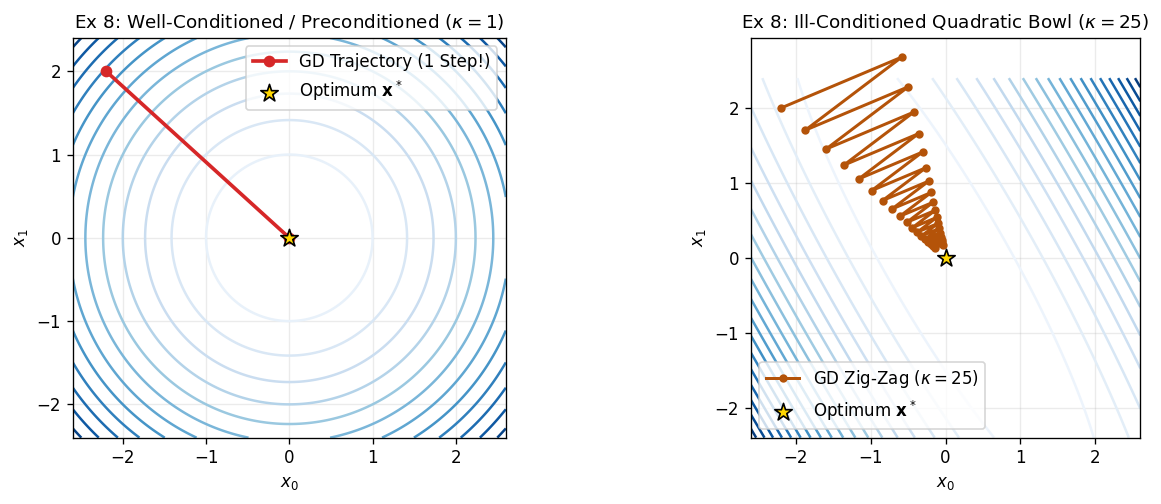

In [8]:
# --- Exercise 8 Verification: Condition Number, Gradient Descent & Preconditioning ---
A8 = np.array([[2., 1.],
               [1., 2.]])
kappa_A8 = np.linalg.cond(A8, p=2)
kappa_manual8 = np.linalg.norm(A8, ord=2) * np.linalg.norm(np.linalg.inv(A8), ord=2)

# Preconditioner P = A^{-1/2} via eigendecomposition
eigvals8, V8 = np.linalg.eigh(A8)
P8 = V8 @ np.diag(1.0 / np.sqrt(eigvals8)) @ V8.T
PtAP8 = P8.T @ A8 @ P8

print("Exercise 8 — Condition Number & Preconditioning:")
print(f"  1. kappa(A) = {kappa_A8:.4f} == ||A||_2 * ||A^{{-1}}||_2 = {kappa_manual8:.4f}")
print(f"  3. Preconditioned P^T A P =\n{PtAP8.round(6)}\n     kappa(P^T A P) = {np.linalg.cond(PtAP8, p=2):.6f}")

# Compare 2D trajectories: Well-conditioned (kappa=1) vs. Ill-conditioned (kappa=25)
def run_gd(A, b, x0, lr, steps=40):
    traj = [x0.copy()]
    x = x0.copy()
    for _ in range(steps):
        grad = A @ x - b
        x = x - lr * grad
        traj.append(x.copy())
        if np.linalg.norm(A @ x - b) < 1e-10:
            break
    return np.array(traj)

# Rotate an ill-conditioned diagonal matrix by 30 degrees so zig-zagging is visually clear
theta_rot = np.deg2rad(30)
R = np.array([[np.cos(theta_rot), -np.sin(theta_rot)],
              [np.sin(theta_rot),  np.cos(theta_rot)]])
A_ill = R @ np.diag([25.0, 1.0]) @ R.T  # kappa = 25
b_ill = np.array([0.0, 0.0])
x_start = np.array([-2.2, 2.0])

# Optimal constant step size for quadratic GD: alpha = 2 / (lambda_max + lambda_min)
lr_ill = 2.0 / (25.0 + 1.0)
traj_ill = run_gd(A_ill, b_ill, x_start, lr=lr_ill, steps=35)

# Well-conditioned (or preconditioned) A_well = 2 * I (kappa = 1), optimal lr = 1/2
A_well = 2.0 * np.eye(2)
traj_well = run_gd(A_well, b_ill, x_start, lr=0.5, steps=10)
print(f"  2. Well-conditioned (kappa=1) steps to convergence: {len(traj_well)-1} step!")
print(f"     Ill-conditioned (kappa=25) error after 1 step:   {np.linalg.norm(traj_ill[1]):.4f} (zig-zags slowly)")

# Plot 2D contours and trajectories
xg, yg = np.meshgrid(np.linspace(-2.6, 2.6, 200), np.linspace(-2.4, 2.4, 200))
pts = np.stack([xg, yg], axis=-1)
zg_ill = 0.5 * np.einsum("...i,ij,...j->...", pts, A_ill, pts)
zg_well = 0.5 * np.einsum("...i,ij,...j->...", pts, A_well, pts)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
axes[0].contour(xg, yg, zg_well, levels=12, cmap="Blues")
axes[0].plot(traj_well[:, 0], traj_well[:, 1], "o-", color="#d62728", lw=2.2, ms=6, label="GD Trajectory (1 Step!)")
axes[0].scatter([0], [0], color="gold", edgecolor="black", s=120, zorder=5, marker="*", label=r"Optimum $\mathbf{x}^*$")
axes[0].set_title(r"Ex 8: Well-Conditioned / Preconditioned ($\kappa = 1$)")
axes[0].set_xlabel(r"$x_0$"); axes[0].set_ylabel(r"$x_1$"); axes[0].set_aspect("equal"); axes[0].legend()

axes[1].contour(xg, yg, zg_ill, levels=18, cmap="Blues")
axes[1].plot(traj_ill[:, 0], traj_ill[:, 1], "o-", color="#b45309", lw=1.8, ms=4, label=r"GD Zig-Zag ($\kappa = 25$)")
axes[1].scatter([0], [0], color="gold", edgecolor="black", s=120, zorder=5, marker="*", label=r"Optimum $\mathbf{x}^*$")
axes[1].set_title(r"Ex 8: Ill-Conditioned Quadratic Bowl ($\kappa = 25$)")
axes[1].set_xlabel(r"$x_0$"); axes[1].set_ylabel(r"$x_1$"); axes[1].set_aspect("equal"); axes[1].legend()
plt.tight_layout()
plt.show()

In [9]:
# --- 5.2 Low-Rank Adaptation (LoRA) & Softmax Attention Rank Expansion ---
rng = np.random.default_rng(0)

# 1. LoRA bottleneck: Delta_W = B @ A for d_out=512, d_in=512, rank r=8
d_model, r_lora = 512, 8
B_lora = rng.standard_normal((d_model, r_lora))
A_lora = rng.standard_normal((r_lora, d_model))
Delta_W = B_lora @ A_lora
full_params = d_model * d_model
lora_params = d_model * r_lora + r_lora * d_model

print("1. Low-Rank Adaptation (LoRA) Matrix Bottleneck:")
print(f"   Delta_W shape: {Delta_W.shape} | rank(B @ A) = {np.linalg.matrix_rank(Delta_W)} == r = {r_lora}")
print(f"   Parameter count: {lora_params:,} vs. Full matrix {full_params:,} ({100 * lora_params / full_params:.2f}% of parameters)")

# 2. Softmax Rank Expansion: Rank-1 outer product M = x x^T -> exp(M) -> Softmax(M) -> Causal Masked Softmax
n_seq = 100
x_vec = rng.standard_normal(n_seq)
M_rank1 = np.outer(x_vec, x_vec)
E_mat = np.exp(M_rank1)
S_encoder = E_mat / E_mat.sum(axis=1, keepdims=True)  # Row-normalized Softmax: D^{-1} exp(M)

# Decoder causal attention: lower-triangular mask with positive diagonal
S_decoder = np.tril(E_mat)
S_decoder = S_decoder / S_decoder.sum(axis=1, keepdims=True)

print("\n2. How Nonlinear Softmax & Causal Masking Break the Attention Rank Bottleneck (n=100):")
print(f"   rank(M = x x^T)         = {np.linalg.matrix_rank(M_rank1):3d}  (Rank-1 linear outer product)")
print(f"   rank(exp(M))            = {np.linalg.matrix_rank(E_mat):3d}  (Element-wise exp mixes Hadamard powers M^(k)/k!)")
print(f"   rank(Softmax(M))        = {np.linalg.matrix_rank(S_encoder):3d}  (Row scaling D^(-1) exp(M) preserves rank = 16!)")
print(f"   rank(CausalSoftmax(M))  = {np.linalg.matrix_rank(S_decoder):3d}  (Triangular mask with positive diagonal -> Full Rank N!)")

1. Low-Rank Adaptation (LoRA) Matrix Bottleneck:
   Delta_W shape: (512, 512) | rank(B @ A) = 8 == r = 8
   Parameter count: 8,192 vs. Full matrix 262,144 (3.12% of parameters)

2. How Nonlinear Softmax & Causal Masking Break the Attention Rank Bottleneck (n=100):
   rank(M = x x^T)         =   1  (Rank-1 linear outer product)
   rank(exp(M))            =  17  (Element-wise exp mixes Hadamard powers M^(k)/k!)
   rank(Softmax(M))        =  18  (Row scaling D^(-1) exp(M) preserves rank = 16!)
   rank(CausalSoftmax(M))  = 100  (Triangular mask with positive diagonal -> Full Rank N!)
